In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("ecommerce_dirty_dataset.csv")

# Data Inspection

In [3]:
df.head(5)

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
0,1,2022-04-13,2022-04-14,1992,Consumer,East,Odisha,Clothing,Kids,Kids Product 3,14492.0,5,0.20,1621.85,328.0,Cash on Delivery
1,2,2023-03-12,2023-03-13,4347,Corporate,East,Bihar,Electronics,Laptop,Laptop Product 100,47633.0,1,0.05,5774.48,340.0,Cash on Delivery
2,3,2022-09-28,2022-10-04,2195,Corporate,West,Maharashtra,Clothing,Women,Women Product 1,4058.1,1,0.10,521.04,348.0,Credit Card
3,4,2022-04-17,2022-04-21,3425,Consumer,South,Tamil Nadu,Electronics,Laptop,Laptop Product 139,61980.0,4,0.00,6695.36,62.0,Cash on Delivery
4,5,2022-03-13,2022-03-20,2967,NaN,North,Haryana,Clothing,Women,Women Product 50,6807.0,3,0.00,2653.83,94.0,Debit Card


In [4]:
df.shape

(100500, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100500 entries, 0 to 100499
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Order_ID          100500 non-null  int64  
 1   Order_Date        100500 non-null  object 
 2   Ship_Date         100500 non-null  object 
 3   Customer_ID       100500 non-null  int64  
 4   Customer_Segment  97481 non-null   object 
 5   Region            100500 non-null  object 
 6   State             100500 non-null  object 
 7   Product_Category  100500 non-null  object 
 8   Sub_Category      100500 non-null  object 
 9   Product_Name      100500 non-null  object 
 10  Sales             100500 non-null  float64
 11  Quantity          100500 non-null  int64  
 12  Discount          100500 non-null  float64
 13  Profit            97481 non-null   float64
 14  Shipping_Cost     97494 non-null   float64
 15  Payment_Mode      100500 non-null  object 
dtypes: float64(4), int64

In [6]:
df.isnull().sum()

Order_ID               0
Order_Date             0
Ship_Date              0
Customer_ID            0
Customer_Segment    3019
Region                 0
State                  0
Product_Category       0
Sub_Category           0
Product_Name           0
Sales                  0
Quantity               0
Discount               0
Profit              3019
Shipping_Cost       3006
Payment_Mode           0
dtype: int64

# Data Type Conversion

In [7]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'],errors='coerce')
df['Ship_Date'] = pd.to_datetime(df['Ship_Date'],errors = 'coerce' )

In [8]:
df[['Sales','Profit']] = df[['Sales','Profit']].apply(lambda x : pd.to_numeric(x,errors='coerce'))

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100500 entries, 0 to 100499
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Order_ID          100500 non-null  int64         
 1   Order_Date        100500 non-null  datetime64[ns]
 2   Ship_Date         100500 non-null  datetime64[ns]
 3   Customer_ID       100500 non-null  int64         
 4   Customer_Segment  97481 non-null   object        
 5   Region            100500 non-null  object        
 6   State             100500 non-null  object        
 7   Product_Category  100500 non-null  object        
 8   Sub_Category      100500 non-null  object        
 9   Product_Name      100500 non-null  object        
 10  Sales             100500 non-null  float64       
 11  Quantity          100500 non-null  int64         
 12  Discount          100500 non-null  float64       
 13  Profit            97481 non-null   float64       
 14  Ship

# Data Cleaning

In [10]:
df['Product_Category'].unique()

array(['Clothing', 'Electronics', 'Furniture', 'ELECTRONICS',
       'electronics'], dtype=object)

In [11]:
df['Product_Category'] = df['Product_Category'].str.strip().str.title()

In [12]:
df['Product_Category'].unique()

array(['Clothing', 'Electronics', 'Furniture'], dtype=object)

In [13]:
df[df['Ship_Date']< df['Order_Date']]

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
58,59,2022-04-02,2022-03-31,2571,Corporate,West,Rajasthan,Furniture,Chair,Chair Product 187,33548.80,4,0.20,NaN,336.0,Debit Card
387,388,2023-05-21,2023-05-19,1735,Home Office,East,Bihar,Electronics,Laptop,Laptop Product 130,173593.50,5,0.05,60824.90,440.0,Debit Card
657,658,2022-04-27,2022-04-25,4586,Home Office,South,Tamil Nadu,Electronics,Accessories,Accessories Product 62,93864.75,3,0.05,17035.33,313.0,UPI
732,733,2023-11-20,2023-11-18,2464,Corporate,East,West Bengal,Clothing,Men,Men Product 76,15990.20,4,0.15,4520.68,327.0,Credit Card
1587,1588,2022-08-12,2022-08-10,2328,Corporate,West,Maharashtra,Electronics,Mobile,Mobile Product 125,189434.40,4,0.15,26407.61,221.0,Debit Card
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99963,99964,2022-10-02,2022-09-30,1478,Consumer,South,Karnataka,Furniture,Table,Table Product 169,25411.20,3,0.20,8290.54,248.0,Cash on Delivery
100068,17251,2022-03-02,2022-02-28,2209,Home Office,North,Haryana,Clothing,Kids,Kids Product 8,3717.00,2,0.10,1079.06,371.0,Debit Card
100250,16460,2023-02-28,2023-02-26,4563,Consumer,East,West Bengal,Furniture,Sofa,Sofa Product 53,7024.50,1,0.10,1947.89,418.0,Debit Card
100285,24425,2022-06-12,2022-06-10,4611,Consumer,West,Rajasthan,Furniture,Sofa,Sofa Product 131,9116.00,1,0.00,3340.11,NaN,Debit Card


In [14]:
df = df[ df['Ship_Date'] >= df['Order_Date'] ]

In [15]:
df[df['Ship_Date']< df['Order_Date']]

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode


In [16]:
negative_sales = df[df['Sales'] < 0]

In [17]:
negative_sales

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
470,471,2022-07-23,2022-07-25,4375,Corporate,East,Odisha,Electronics,Accessories,Accessories Product 54,-5000.0,5,0.15,75466.83,428.0,UPI
1706,1707,2022-03-25,2022-03-26,1749,Consumer,East,West Bengal,Furniture,Chair,Chair Product 160,-5000.0,2,0.10,8349.24,58.0,UPI
3627,3628,2023-04-01,2023-04-06,1171,Home Office,North,Haryana,Electronics,Laptop,Laptop Product 182,-5000.0,5,0.05,51986.61,207.0,Cash on Delivery
4186,4187,2022-04-10,2022-04-17,4931,Consumer,West,Maharashtra,Clothing,Women,Women Product 177,-5000.0,2,0.00,2105.71,443.0,UPI
6067,6068,2023-03-18,2023-03-22,2880,Consumer,North,Haryana,Clothing,Men,Men Product 184,-5000.0,3,0.00,2326.83,239.0,Debit Card
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97644,97645,2023-10-08,2023-10-13,1794,Home Office,North,Punjab,Electronics,Accessories,Accessories Product 149,-5000.0,2,0.05,21369.92,250.0,Debit Card
98510,98511,2022-04-01,2022-04-05,3314,Consumer,North,Punjab,Clothing,Men,Men Product 164,-5000.0,4,0.05,4090.01,296.0,Credit Card
99372,99373,2022-01-30,2022-01-31,4328,Corporate,West,Gujarat,Clothing,Men,Men Product 65,-5000.0,5,0.00,1627.84,109.0,Debit Card
99757,99758,2022-09-26,2022-09-30,4199,Consumer,North,Haryana,Clothing,Women,Women Product 72,-5000.0,4,0.05,2350.66,130.0,Debit Card


In [18]:
df = df[df['Sales']>=0]

In [19]:
df[df['Sales']<0]

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode


In [20]:
high_discount = df[df['Discount']>0.80]
high_discount

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
516,517,2023-05-14,2023-05-18,1820,Corporate,East,West Bengal,Clothing,Kids,Kids Product 154,19679.25,5,0.9,6259.19,474.0,UPI
1126,1127,2023-04-07,2023-04-08,1548,Corporate,North,Delhi,Furniture,Table,Table Product 42,42547.50,5,0.9,6770.94,368.0,UPI
1494,1495,2023-01-11,2023-01-15,3962,Corporate,North,Punjab,Furniture,Sofa,Sofa Product 176,12301.55,1,0.9,4431.19,482.0,Credit Card
2123,2124,2023-06-23,2023-06-27,4468,Corporate,North,Haryana,Furniture,Sofa,Sofa Product 57,4675.00,1,0.9,1471.27,162.0,UPI
3329,3330,2023-03-05,2023-03-11,4787,Corporate,West,Maharashtra,Clothing,Men,Men Product 3,20372.75,5,0.9,6280.52,102.0,Cash on Delivery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98895,98896,2022-05-26,2022-06-02,4124,Consumer,East,Odisha,Clothing,Women,Women Product 57,1910.40,2,0.9,752.05,475.0,UPI
100009,609,2023-01-28,2023-02-02,1572,Corporate,East,Bihar,Furniture,Sofa,Sofa Product 130,49047.60,4,0.9,7961.32,406.0,Cash on Delivery
100095,75591,2023-06-19,2023-06-21,3350,Consumer,East,Odisha,Furniture,Table,Table Product 165,29772.80,4,0.9,5886.19,326.0,Credit Card
100196,52971,2022-10-26,2022-10-28,1311,Consumer,South,Telangana,Furniture,Sofa,Sofa Product 192,25622.40,4,0.9,4272.50,252.0,UPI


In [21]:
high_discount[['Sales','Profit']].sum()

Sales     8657790.75
Profit    2170819.45
dtype: float64

In [22]:
df['Shipping_Cost'].unique()

array([  328.,   340.,   348.,    62.,    94.,   322.,   103.,   249.,
          nan,   202.,   149.,    68.,   204.,   435.,   368.,   231.,
         377.,   130.,   216.,   136.,   273.,   374.,   481.,   460.,
         317.,   285.,   210.,   171.,   381.,   442.,   309.,   262.,
         159.,   308.,   346.,   297.,   408.,   287.,   311.,   110.,
         218.,   413.,   352.,   212.,   395.,   398.,   147.,    83.,
         407.,   493.,   483.,   239.,   380.,   301.,   492.,   294.,
         456.,   277.,   307.,   161.,   158.,   278.,    65.,   124.,
         230.,   104.,   128.,   445.,   167.,   436.,   175.,   338.,
         360.,   357.,    78.,    87.,   305.,   464.,   282.,    64.,
         193.,   150.,   370.,   120.,   313.,   382.,   179.,   453.,
          71.,   118.,   222.,   375.,   496.,   471.,    58.,    55.,
         247.,   400.,   478.,   116.,   224.,   303.,   397.,   430.,
         422.,   156.,   186.,   482.,   333.,   199.,   180.,   172.,
      

In [23]:
(df['Shipping_Cost'] == 10000).sum()

np.int64(99)

In [24]:
df['Shipping_Cost'].describe()

count    97061.000000
mean       285.268151
std        336.481541
min         50.000000
25%        163.000000
50%        276.000000
75%        388.000000
max      10000.000000
Name: Shipping_Cost, dtype: float64

In [25]:
Q1 = df['Shipping_Cost'].quantile(0.25)
Q3 = df['Shipping_Cost'].quantile(0.75)
IQR = Q3 - Q1 
upper_limit = Q3 + 1.5 * IQR
df['Shipping_Cost'] = df['Shipping_Cost'].clip(upper = upper_limit)

In [26]:
df['Shipping_Cost'].describe()

count    97061.000000
mean       275.808373
std        130.635555
min         50.000000
25%        163.000000
50%        276.000000
75%        388.000000
max        725.500000
Name: Shipping_Cost, dtype: float64

In [27]:
df['Profit'].describe()

count     97042.000000
mean      13122.517107
std       21751.620754
min          36.040000
25%        1762.970000
50%        5103.715000
75%       15579.957500
max      500000.000000
Name: Profit, dtype: float64

In [28]:
(df['Profit'] == 500000).sum()

np.int64(50)

In [29]:
df = df[df['Profit']!=500000]

In [30]:
(df['Profit'] == 500000).sum()

np.int64(0)

In [31]:
df['Profit'].describe()

count     96992.000000
mean      12871.528632
std       18737.983308
min          36.040000
25%        1761.707500
50%        5097.415000
75%       15556.820000
max      157051.000000
Name: Profit, dtype: float64

In [32]:
Q1 = df['Profit'].quantile(0.25)
Q3 = df['Profit'].quantile(0.75)
IQR = Q3 - Q1 
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
lower_outliers  = df[df['Profit']<lower_limit]
upper_outliers  = df[df['Profit']>upper_limit]
print(len(lower_outliers),len(upper_outliers))


0 9626


In [33]:
df['Profit'] = df['Profit'].clip(upper = upper_limit)

In [34]:
df['Profit'].describe()

count    96992.000000
mean     10513.923346
std      11663.644467
min         36.040000
25%       1761.707500
50%       5097.415000
75%      15556.820000
max      36249.488750
Name: Profit, dtype: float64

In [35]:
df.isnull().sum()

Order_ID               0
Order_Date             0
Ship_Date              0
Customer_ID            0
Customer_Segment    3003
Region                 0
State                  0
Product_Category       0
Sub_Category           0
Product_Name           0
Sales                  0
Quantity               0
Discount               0
Profit              3008
Shipping_Cost       2987
Payment_Mode           0
dtype: int64

In [36]:
df['Customer_Segment'] = df['Customer_Segment'].fillna('Unknown')

In [37]:
df['Shipping_Cost'] = df['Shipping_Cost'].fillna(df['Shipping_Cost'].median())

In [38]:
duplicates = df[df.duplicated(keep = False)]

In [39]:
duplicates.sort_values('Order_ID')

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Segment,Region,State,Product_Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit,Shipping_Cost,Payment_Mode
100329,253,2023-12-12,2023-12-16,2807,Home Office,West,Rajasthan,Clothing,Kids,Kids Product 45,14305.00,5,0.00,3256.81000,362.0,UPI
252,253,2023-12-12,2023-12-16,2807,Home Office,West,Rajasthan,Clothing,Kids,Kids Product 45,14305.00,5,0.00,3256.81000,362.0,UPI
330,331,2023-09-01,2023-09-04,3235,Corporate,North,Delhi,Electronics,Laptop,Laptop Product 89,185283.00,3,0.00,36249.48875,197.0,Cash on Delivery
100367,331,2023-09-01,2023-09-04,3235,Corporate,North,Delhi,Electronics,Laptop,Laptop Product 89,185283.00,3,0.00,36249.48875,197.0,Cash on Delivery
100408,418,2022-02-22,2022-02-24,1606,Consumer,East,Odisha,Clothing,Men,Men Product 177,2047.00,2,0.50,335.46000,296.0,Debit Card
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99297,99298,2022-11-21,2022-11-28,3077,Corporate,South,Tamil Nadu,Clothing,Kids,Kids Product 35,1220.00,2,0.00,184.09000,229.0,Cash on Delivery
100021,99820,2023-12-01,2023-12-05,3609,Consumer,South,Karnataka,Electronics,Mobile,Mobile Product 108,35548.80,2,0.20,7936.13000,130.0,Debit Card
99819,99820,2023-12-01,2023-12-05,3609,Consumer,South,Karnataka,Electronics,Mobile,Mobile Product 108,35548.80,2,0.20,7936.13000,130.0,Debit Card
99901,99902,2023-01-10,2023-01-12,3703,Unknown,North,Punjab,Clothing,Kids,Kids Product 132,16553.75,5,0.05,NaN,490.0,UPI


In [40]:
df = df.drop_duplicates()

In [41]:
df.shape

(99518, 16)

In [42]:
df.duplicated().sum()

np.int64(0)

In [43]:
df.isnull().sum()

Order_ID               0
Order_Date             0
Ship_Date              0
Customer_ID            0
Customer_Segment       0
Region                 0
State                  0
Product_Category       0
Sub_Category           0
Product_Name           0
Sales                  0
Quantity               0
Discount               0
Profit              2989
Shipping_Cost          0
Payment_Mode           0
dtype: int64

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 99518 entries, 0 to 100496
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          99518 non-null  int64         
 1   Order_Date        99518 non-null  datetime64[ns]
 2   Ship_Date         99518 non-null  datetime64[ns]
 3   Customer_ID       99518 non-null  int64         
 4   Customer_Segment  99518 non-null  object        
 5   Region            99518 non-null  object        
 6   State             99518 non-null  object        
 7   Product_Category  99518 non-null  object        
 8   Sub_Category      99518 non-null  object        
 9   Product_Name      99518 non-null  object        
 10  Sales             99518 non-null  float64       
 11  Quantity          99518 non-null  int64         
 12  Discount          99518 non-null  float64       
 13  Profit            96529 non-null  float64       
 14  Shipping_Cost     99518 no

In [45]:
(df['Ship_Date']<df['Order_Date']).sum()

np.int64(0)

In [46]:
(df['Sales']<0).sum()

np.int64(0)

# Feature Engineering

In [47]:
df['Order_Year'] = df['Order_Date'].dt.year

In [48]:
df['Order_Month'] = df['Order_Date'].dt.month

In [49]:
df['Order_Quarter'] = df['Order_Date'].dt.quarter

In [50]:
df['Shipping_Days'] = (df['Ship_Date'] - df['Order_Date']).dt.days

In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 99518 entries, 0 to 100496
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          99518 non-null  int64         
 1   Order_Date        99518 non-null  datetime64[ns]
 2   Ship_Date         99518 non-null  datetime64[ns]
 3   Customer_ID       99518 non-null  int64         
 4   Customer_Segment  99518 non-null  object        
 5   Region            99518 non-null  object        
 6   State             99518 non-null  object        
 7   Product_Category  99518 non-null  object        
 8   Sub_Category      99518 non-null  object        
 9   Product_Name      99518 non-null  object        
 10  Sales             99518 non-null  float64       
 11  Quantity          99518 non-null  int64         
 12  Discount          99518 non-null  float64       
 13  Profit            96529 non-null  float64       
 14  Shipping_Cost     99518 no

In [52]:
#df.to_csv('Ecommerce_Cleaned_Dataset.csv',index = False)
print("successfully downloaded the cleaned Ecommerce csv file!")

successfully downloaded the cleaned Ecommerce csv file!


# Exploratory Data Analysis

## A.Univariate Analysis

In [53]:
columns = ['Sales','Profit','Quantity','Discount','Shipping_Cost']

df[columns].describe()

,Sales,Profit,Quantity,Discount,Shipping_Cost
count,99518.000000,96529.000000,99518.000000,99518.000000,99518.000000
mean,51437.860045,10512.095905,2.997910,0.120206,275.822876
std,68935.934971,11662.852718,1.414617,0.113501,128.648581
min,292.000000,36.040000,1.000000,0.000000,50.000000
25%,7867.825000,1760.370000,2.000000,0.050000,166.000000
50%,21356.500000,5097.250000,3.000000,0.100000,276.000000
75%,63526.550000,15554.020000,4.000000,0.200000,385.000000
max,399965.000000,36249.488750,5.000000,0.900000,725.500000


In [54]:
df[columns].skew()

Sales            2.124044
Profit           1.203674
Quantity        -0.001098
Discount         1.835925
Shipping_Cost    0.026988
dtype: float64

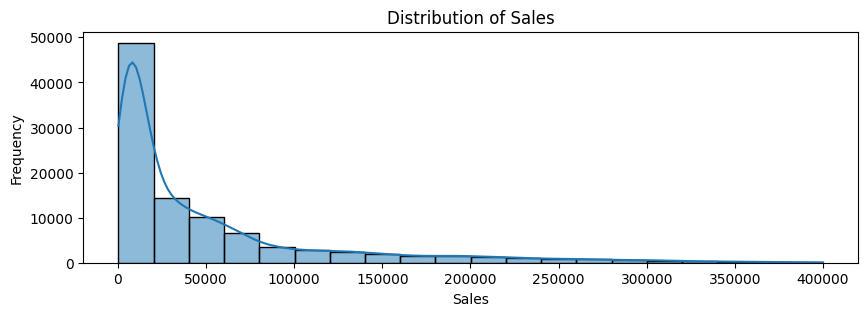

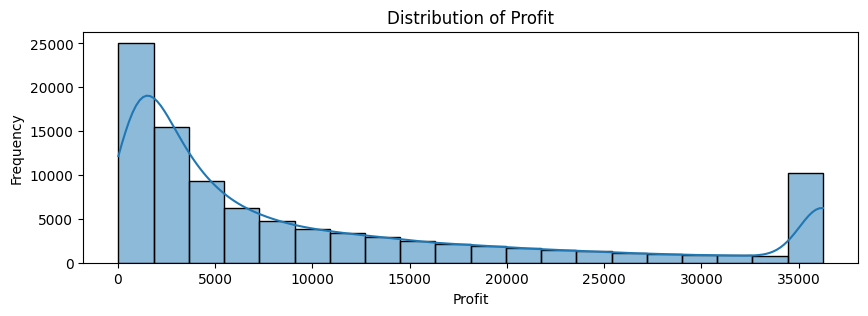

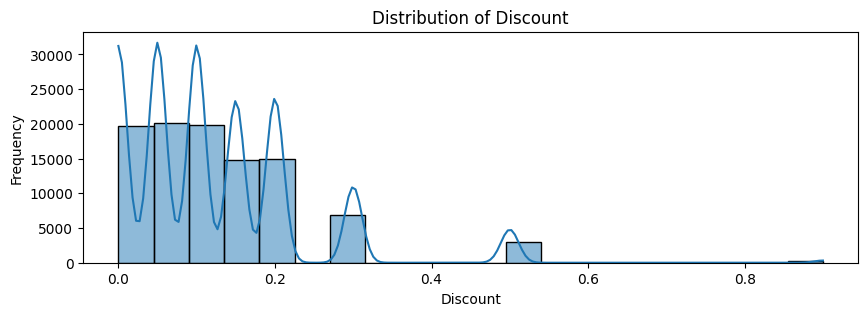

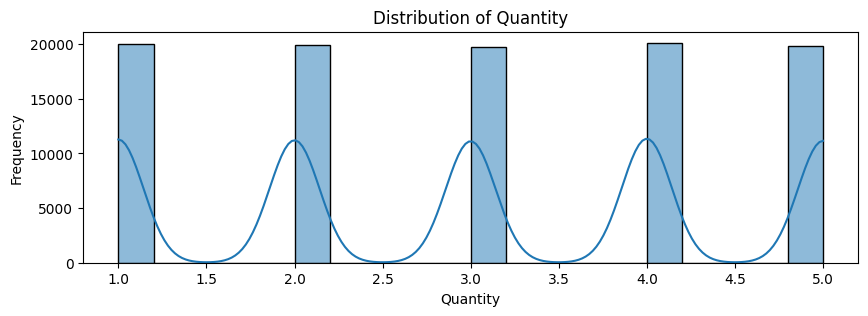

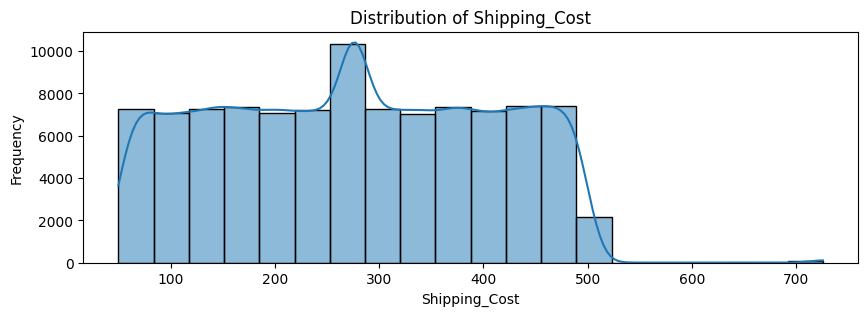

In [55]:
# Histogram

#Sales
plt.figure(figsize=(10,3))
sns.histplot(data = df['Sales'],bins = 20, kde = True)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

#profit
plt.figure(figsize=(10,3))
sns.histplot(data = df['Profit'],bins = 20 , kde = True)
plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

#Discount
plt.figure(figsize=(10,3))
sns.histplot(data = df['Discount'],bins = 20, kde = True)
plt.title("Distribution of Discount")
plt.xlabel("Discount")
plt.ylabel("Frequency")
plt.show()

#Quantity
plt.figure(figsize=(10,3))
sns.histplot(data = df['Quantity'],bins = 20 , kde = True)
plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.show()


#Shipping_Cost
plt.figure(figsize=(10,3))
sns.histplot(data = df['Shipping_Cost'],bins = 20 , kde = True)
plt.title("Distribution of Shipping_Cost")
plt.xlabel("Shipping_Cost")
plt.ylabel("Frequency")
plt.show()

In [56]:
#IQR method to find outliers
for col in columns:
     
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
     
    IQR = Q3 - Q1
     
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
     
    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]
     
    print(col , ":" , len(outliers))


Sales : 10157
Profit : 9581
Quantity : 0
Discount : 3221
Shipping_Cost : 98


## B. Categorical Analysis

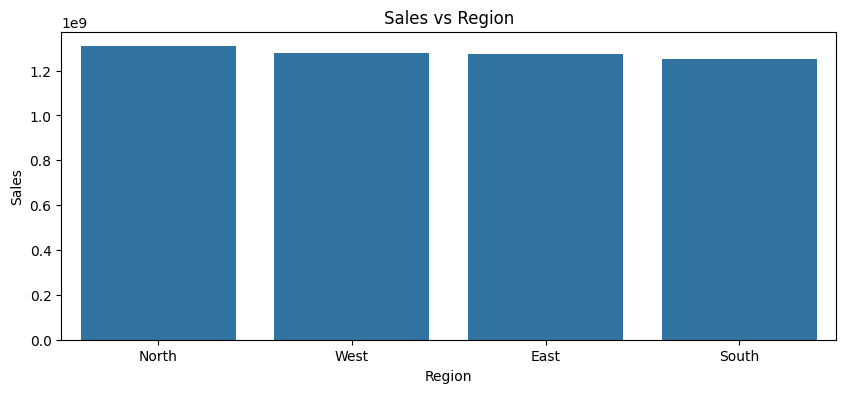

In [57]:
# Sales by Region
region_sales =  df.groupby('Region')['Sales'].sum().reset_index().sort_values('Sales',ascending = False)
plt.figure(figsize=(10,4))
sns.barplot(data = region_sales,x='Region',y='Sales')
plt.title("Sales vs Region")
plt.show()


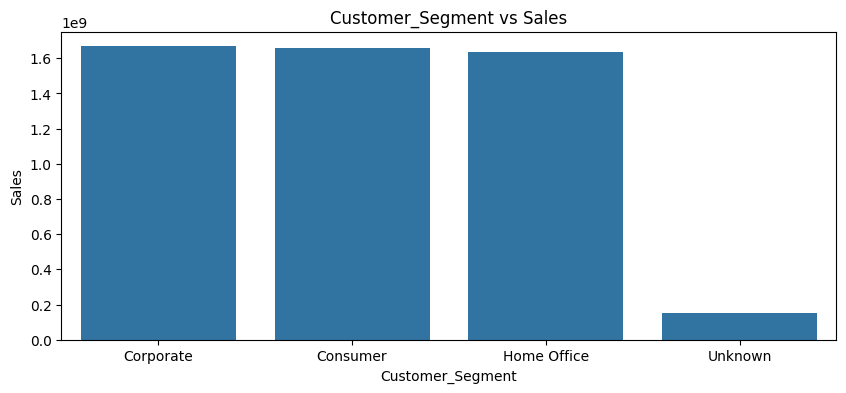

In [58]:
#Customer_Segment vs Sales
customer_segment_sales = df.groupby('Customer_Segment')['Sales'].sum().reset_index().sort_values('Sales',ascending = False)
plt.figure(figsize=(10,4))
sns.barplot(data = customer_segment_sales , x='Customer_Segment',y='Sales')
plt.title("Customer_Segment vs Sales")
plt.show()

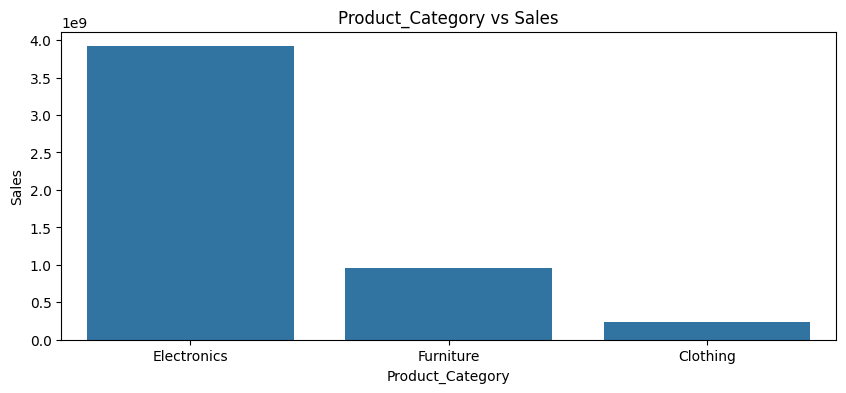

In [59]:
# sales by product category
product_category_sales = df.groupby('Product_Category')['Sales'].sum().reset_index().sort_values('Sales',ascending = False)
plt.figure(figsize = (10,4))
sns.barplot(data = product_category_sales , x='Product_Category',y= 'Sales')
plt.title("Product_Category vs Sales")
plt.show()

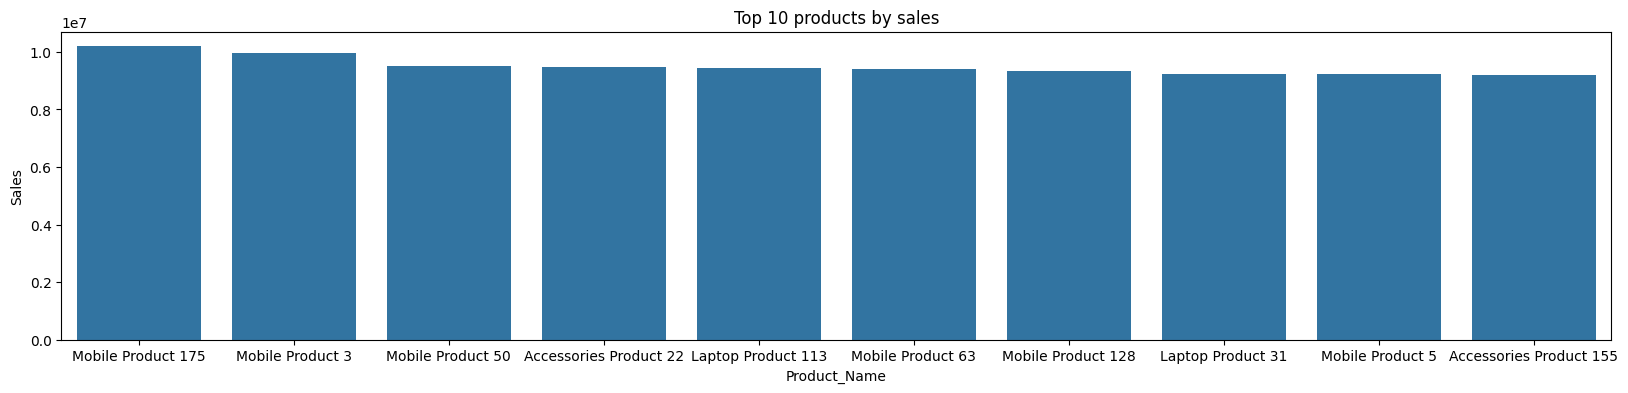

In [60]:
top_products = df.groupby('Product_Name')['Sales'].sum().reset_index().nlargest(10,'Sales')
plt.figure(figsize = (20,4))
sns.barplot(data = top_products , x= 'Product_Name',y= 'Sales')
plt.title("Top 10 products by sales")
plt.show()



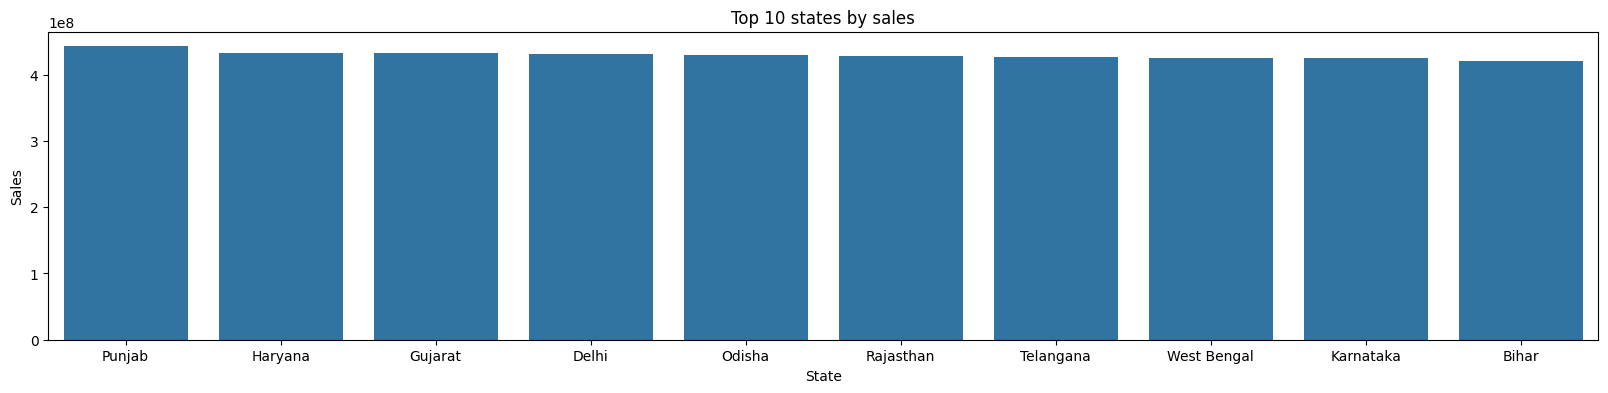

In [61]:
top_10_States = df.groupby('State')['Sales'].sum().reset_index().nlargest(10,'Sales')

plt.figure(figsize = (20,4))
sns.barplot(data = top_10_States , x= 'State',y= 'Sales')
plt.title("Top 10 states by sales")
plt.show()


## C.Bivariate Analysis

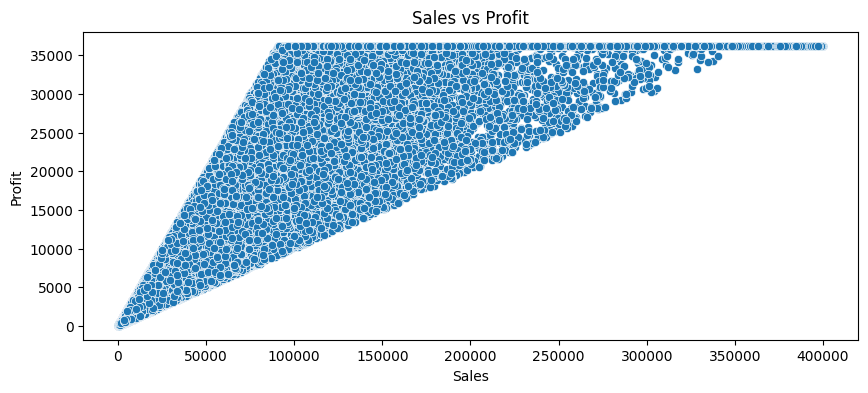

In [62]:
# Sales vs Profit
plt.figure(figsize=(10, 4))
sns.scatterplot(data=df, x='Sales', y='Profit')
plt.title('Sales vs Profit')
plt.show()


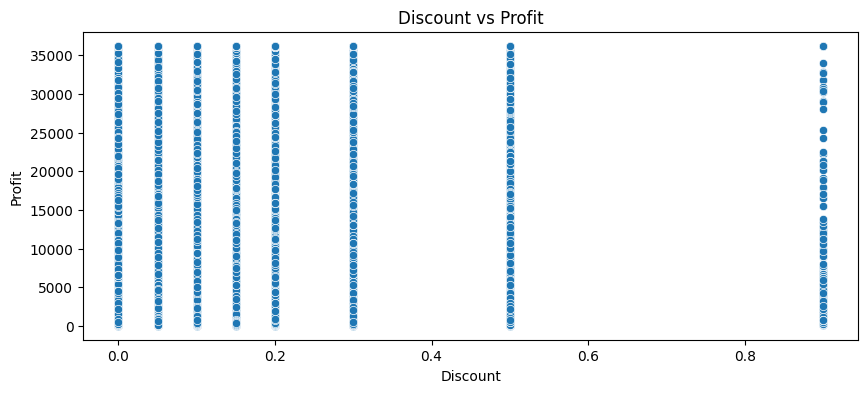

In [63]:
# Discount vs Profit
plt.figure(figsize=(10, 4))
sns.scatterplot(data=df, x='Discount', y='Profit')
plt.title('Discount vs Profit')
plt.show()



In [64]:
discount_profit = df.groupby('Discount')['Profit'].mean()

print(discount_profit)

Discount
0.00    11564.384383
0.05    10958.457744
0.10    10648.288829
0.15    10215.209483
0.20    10044.460435
0.30     8961.162126
0.50     7183.894007
0.90     9299.974391
Name: Profit, dtype: float64


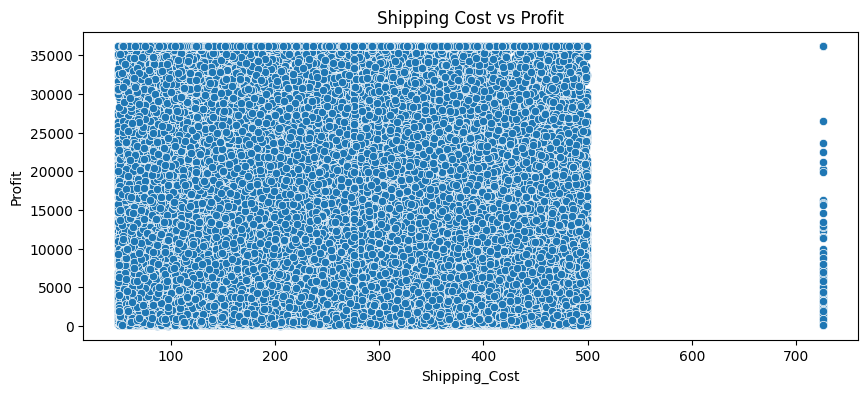

In [65]:
# Shipping Cost vs Profit
plt.figure(figsize=(10, 4))
sns.scatterplot(data=df, x='Shipping_Cost', y='Profit')
plt.title('Shipping Cost vs Profit')
plt.show()


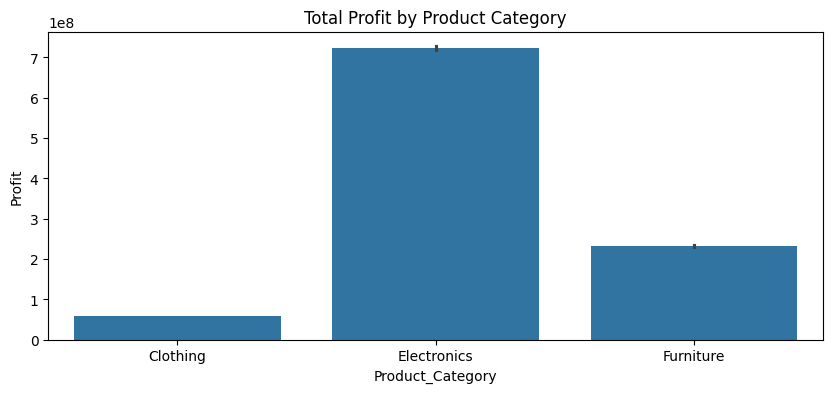

In [66]:
# Product Category vs Profit
plt.figure(figsize=(10, 4))
sns.barplot(data=df, x='Product_Category', y='Profit', estimator='sum')
plt.title('Total Profit by Product Category')
plt.show()


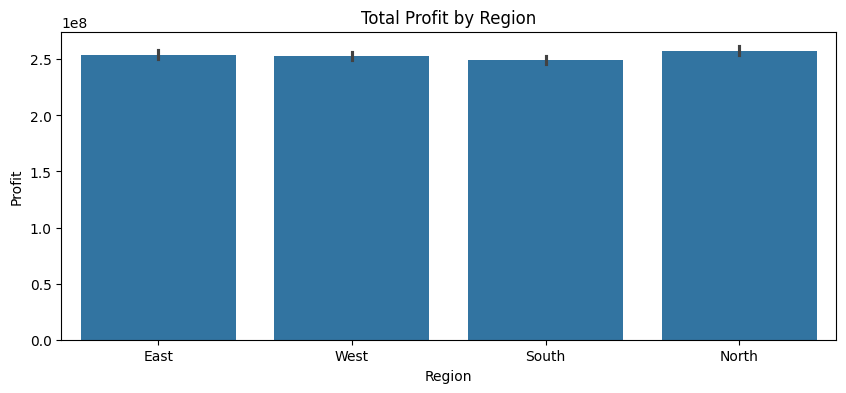

In [67]:
# Region vs Profit
plt.figure(figsize=(10, 4))
sns.barplot(data=df, x='Region', y='Profit', estimator='sum')
plt.title('Total Profit by Region')
plt.show()

## D.Time-based analysis

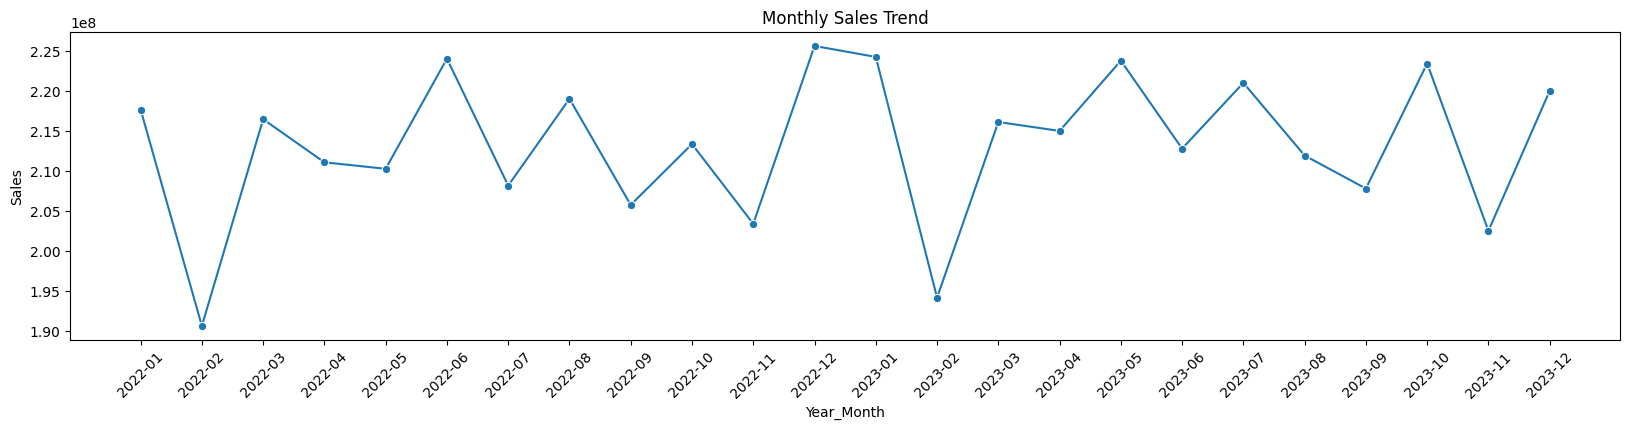

In [68]:

monthly_sales = df.groupby(['Order_Year', 'Order_Month'])['Sales'].sum().reset_index()

monthly_sales['Year_Month'] = (monthly_sales['Order_Year'].astype(str) + '-' +monthly_sales['Order_Month'].astype(str).str.zfill(2))

plt.figure(figsize=(20, 4))
sns.lineplot(data=monthly_sales, x='Year_Month', y='Sales',marker ='o')
plt.title('Monthly Sales Trend')
plt.xticks(rotation=45)
plt.show()

In [69]:
quarterly_sales = df.groupby(['Order_Year', 'Order_Quarter'])['Sales'].sum().reset_index()

quarterly_sales['Growth'] = quarterly_sales['Sales'].pct_change() * 100

print(quarterly_sales)

   Order_Year  Order_Quarter         Sales    Growth
0        2022              1  6.248709e+08       NaN
1        2022              2  6.454682e+08  3.296254
2        2022              3  6.330384e+08 -1.925701
3        2022              4  6.424687e+08  1.489685
4        2023              1  6.346251e+08 -1.220861
5        2023              2  6.516538e+08  2.683272
6        2023              3  6.408234e+08 -1.661988
7        2023              4  6.460445e+08  0.814746


In [70]:
quarterly_sales = df.groupby(['Order_Year', 'Order_Quarter'])['Sales'].sum().reset_index()

quarterly_sales['Growth'] = quarterly_sales['Sales'].pct_change() * 100

print(quarterly_sales)

   Order_Year  Order_Quarter         Sales    Growth
0        2022              1  6.248709e+08       NaN
1        2022              2  6.454682e+08  3.296254
2        2022              3  6.330384e+08 -1.925701
3        2022              4  6.424687e+08  1.489685
4        2023              1  6.346251e+08 -1.220861
5        2023              2  6.516538e+08  2.683272
6        2023              3  6.408234e+08 -1.661988
7        2023              4  6.460445e+08  0.814746


## E.Customer Analysis

In [71]:
#Top 20% customers revenue contribution (Pareto Analysis)

customer_sales = df.groupby('Customer_ID')['Sales'].sum().sort_values(ascending=False)
top_20 = int(len(customer_sales) * 0.20)

top_sales = customer_sales.head(top_20).sum()
total_sales = customer_sales.sum()

contribution = (top_sales / total_sales) * 100

print("Top 20% Customer Sales:", top_sales)
print("Total Sales:", total_sales)
print("Revenue Contribution:", round(contribution, 2), "%")

Top 20% Customer Sales: 1528891020.85
Total Sales: 5118992956.0
Revenue Contribution: 29.87 %


In [72]:
#Repeat customer behavior

customer_orders = df.groupby('Customer_ID')['Order_ID'].nunique()

repeat_customers = customer_orders[customer_orders > 1]

print("Total Customers:", len(customer_orders))
print("Repeat Customers:", len(repeat_customers))

percentage = (len(repeat_customers) / len(customer_orders)) * 100

print("Repeat Customer Percentage:", round(percentage, 2), "%")

Total Customers: 4000
Repeat Customers: 4000
Repeat Customer Percentage: 100.0 %


  Customer_Segment         Sales
0         Consumer  51409.012491
1        Corporate  52158.388963
2      Home Office  50787.217645
3          Unknown  51247.891857


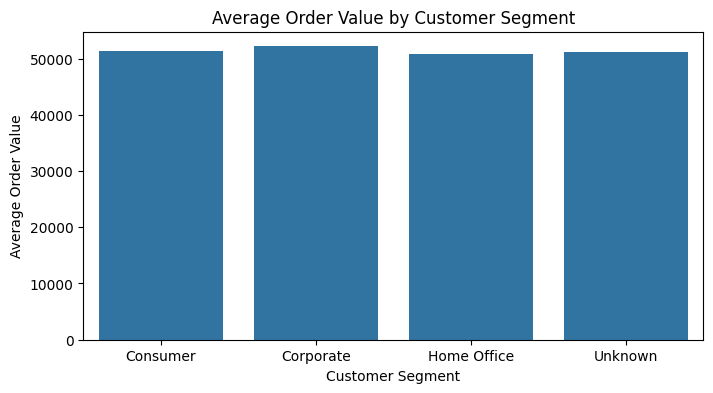

In [73]:
#Average order value per segment

orders = df.groupby('Order_ID').agg({'Sales': 'sum','Customer_Segment': 'first'}).reset_index()

segment_aov = orders.groupby('Customer_Segment')['Sales'].mean().reset_index()

print(segment_aov)

plt.figure(figsize=(8, 4))
sns.barplot(data=segment_aov, x='Customer_Segment', y='Sales')

plt.title('Average Order Value by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Order Value')
plt.show()

## F.Correlation Analysis

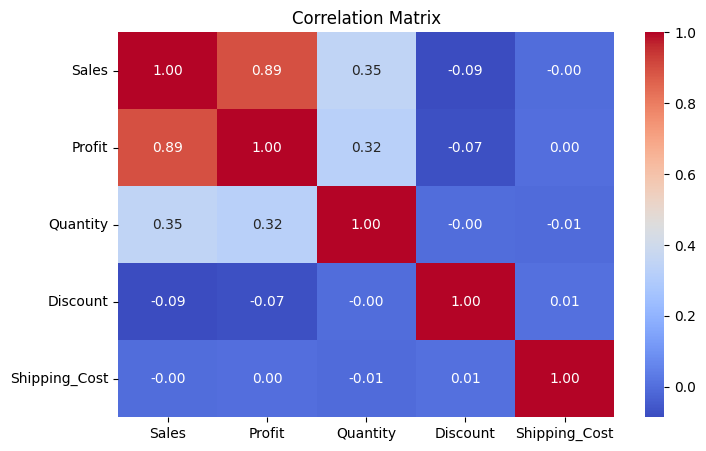

In [74]:
# Correlation Matrix

columns = ['Sales', 'Profit', 'Quantity', 'Discount', 'Shipping_Cost']

correlation = df[columns].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Matrix')
plt.show()

# Insights